[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/04_trampas_de_la_media.ipynb)

# 🦖 Las trampas de la media (y por qué SIEMPRE hay que dibujar los datos)

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM**

Cuatro historias cortas en las que los números resumen **mienten** (o, mejor dicho, no cuentan toda la verdad):

1. **Bill Gates entra en un bar**: la media se vuelve loca y la mediana ni se inmuta.
2. **El cuarteto de Anscombe** (1973): cuatro conjuntos con la misma media, varianza, correlación… y **la misma recta de regresión**.
3. **El Datasaurus**: trece conjuntos con los mismos estadísticos. Uno de ellos es un dinosaurio.
4. **Cinco distribuciones con el mismo diagrama de caja**.
5. **La paradoja de Simpson**: ¿discriminaba la Universidad de Berkeley a las mujeres en 1973?

In [1]:
# ============================================================
# 0. Librerías y estilo de los gráficos
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if v != 0 and abs(v) < 0.01 else f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"

# Los datos están en el repositorio de GitHub: así no hay que subir nada a Colab
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

---
# 🕐 Sesión 1 de 1 · Por qué hay que dibujar los datos
**Objetivos:** robustez de la media y la mediana, límites de los resúmenes numéricos y del R², paradoja de Simpson.  
**Apartados:** 1 a 5 · **Duración orientativa:** 2 horas

## 1. Bill Gates entra en un bar
En un bar hay 10 personas con sueldos normales (en miles de € al año). Entra Bill Gates.

In [2]:
sueldos = pd.Series([18, 21, 22, 24, 25, 27, 28, 31, 35, 40], name="sueldo")
con_gates = pd.concat([sueldos, pd.Series([1_000_000])], ignore_index=True)

comparacion = pd.DataFrame({
    "sin Gates": [sueldos.mean(), sueldos.median(), stats.trim_mean(sueldos, 0.1), sueldos.std(), sueldos.quantile(.75) - sueldos.quantile(.25)],
    "con Gates": [con_gates.mean(), con_gates.median(), stats.trim_mean(con_gates, 0.1), con_gates.std(), con_gates.quantile(.75) - con_gates.quantile(.25)],
}, index=["media", "mediana", "media recortada 10%", "desv. típica", "IQR"])
comparacion.round(1)

,sin Gates,con Gates
media,27.100,"90,933.700"
mediana,26.000,27.000
media recortada 10%,26.600,28.100
desv. típica,6.700,"301,503.200"
IQR,7.800,10.000


🤔 Con Gates en el bar, **la persona media es millonaria**, pero nadie (salvo uno) lo es.
La mediana y el IQR apenas cambian: son medidas **robustas**. La media y la desviación típica, no.
¿Qué medida usarías para hablar del "sueldo típico" de un país?

## 2. El cuarteto de Anscombe
En 1973 el estadístico Francis Anscombe construyó cuatro conjuntos de 11 puntos para demostrar que **hay que dibujar los datos**.

In [3]:
ans = pd.read_csv(URL_DATOS + "anscombe.csv")
tabla_ans = ans.groupby("dataset").agg(media_x=("x", "mean"), media_y=("y", "mean"),
                                       var_x=("x", "var"), var_y=("y", "var"),
                                       desv_x=("x", "std"), desv_y=("y", "std"))
tabla_ans["r"] = [g["x"].corr(g["y"]) for _, g in ans.groupby("dataset")]
tabla_ans["recta_b"] = tabla_ans["r"] * tabla_ans["desv_y"] / tabla_ans["desv_x"]      # b = S_xy / S_x² = r · S_y / S_x
tabla_ans["recta_a"] = tabla_ans["media_y"] - tabla_ans["recta_b"] * tabla_ans["media_x"]
tabla_ans["R2"] = tabla_ans["r"] ** 2
tabla_ans.round(2)

,media_x,media_y,var_x,var_y,desv_x,desv_y,r,recta_b,recta_a,R2
dataset,,,,,,,,,,
I,9.000,7.500,11.000,4.130,3.320,2.030,0.820,0.500,3.000,0.670
II,9.000,7.500,11.000,4.130,3.320,2.030,0.820,0.500,3.000,0.670
III,9.000,7.500,11.000,4.120,3.320,2.030,0.820,0.500,3.000,0.670
IV,9.000,7.500,11.000,4.120,3.320,2.030,0.820,0.500,3.000,0.670


Los cuatro tienen, a dos decimales, **la misma media, la misma varianza, la misma correlación y la misma recta de regresión**
($y = 3 + 0{,}5\,x$, con $R^2 = 0{,}67$). ¿Son iguales? Dibujémoslos:

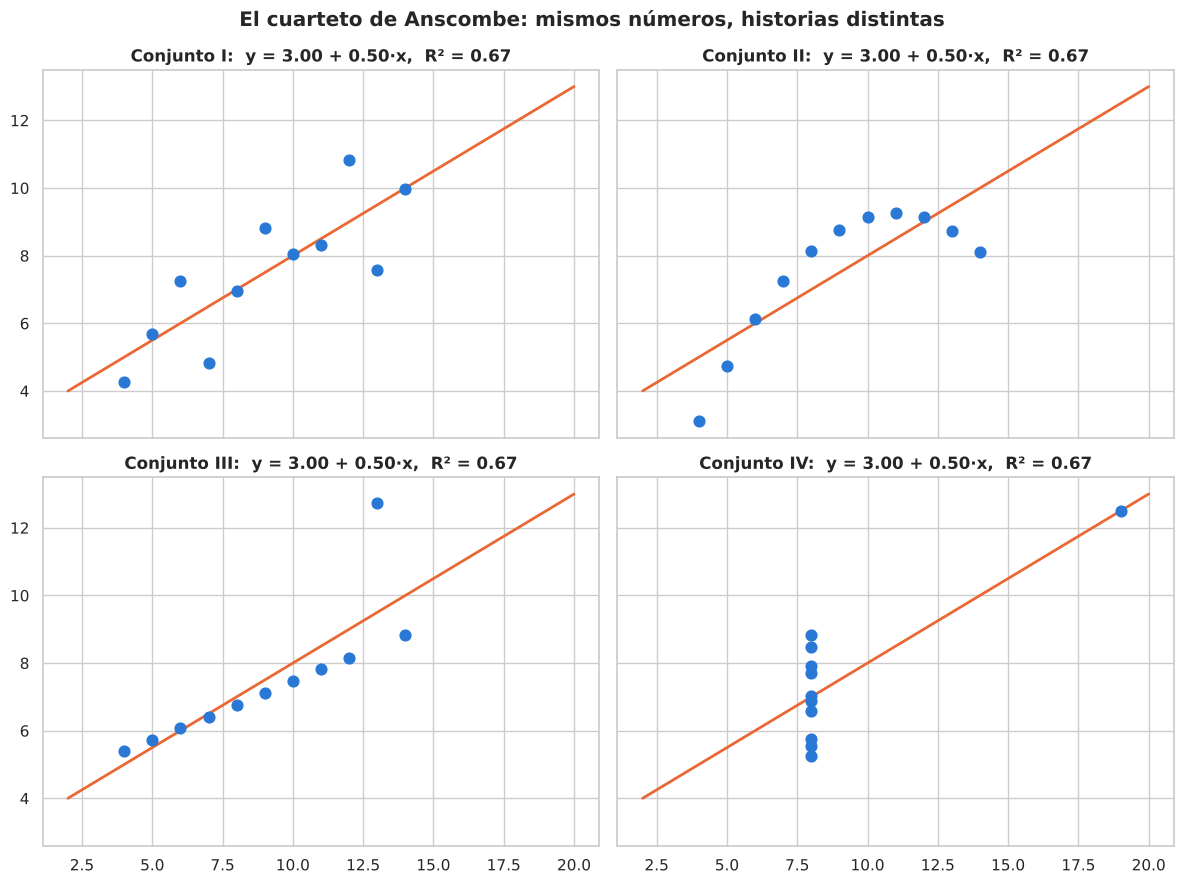

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
xs = np.linspace(2, 20, 50)
for ax, (nombre, g) in zip(axes.flat, ans.groupby("dataset")):
    b = g["x"].cov(g["y"]) / g["x"].var()          # pendiente = covarianza / varianza de x
    a = g["y"].mean() - b * g["x"].mean()
    ax.scatter(g["x"], g["y"], s=60, color=AZUL, zorder=3)
    ax.plot(xs, a + b * xs, color=NARANJA, lw=2)
    ax.set_title(f"Conjunto {nombre}:  y = {a:.2f} + {b:.2f}·x,  R² = {g['x'].corr(g['y'])**2:.2f}")
plt.suptitle("El cuarteto de Anscombe: mismos números, historias distintas", fontweight="bold")
plt.tight_layout(); plt.show()

- **I**: la recta tiene sentido.
- **II**: la relación es **curva**; una recta es el modelo equivocado (y ni el potencial ni el exponencial son la forma correcta: es una parábola).
- **III**: una relación casi perfecta… y **un atípico** que tuerce la recta.
- **IV**: no hay relación ninguna entre x e y; **un único punto** "fabrica" la correlación.

🎯 El $R^2$ no dice si el modelo es el adecuado. **Solo el gráfico (y los residuos) lo dicen.**

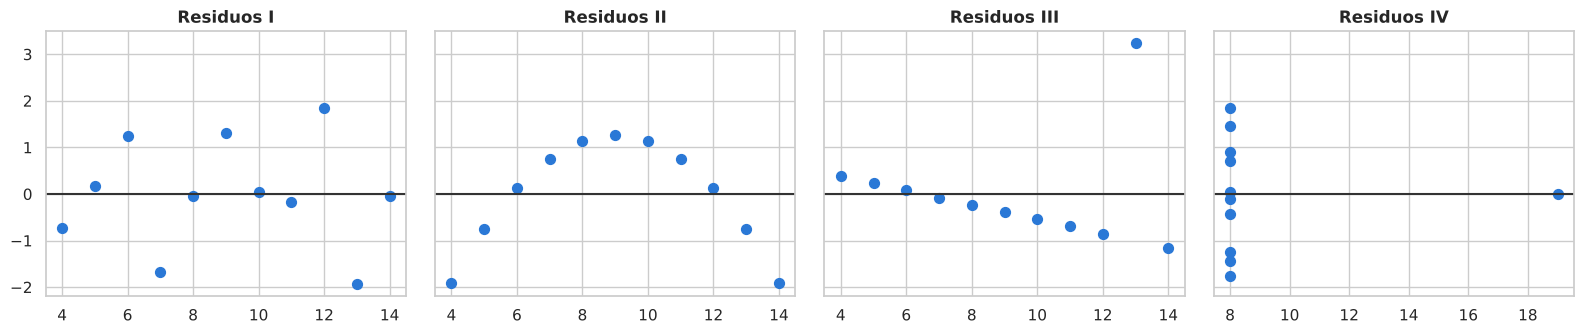

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (nombre, g) in zip(axes, ans.groupby("dataset")):
    b = g["x"].cov(g["y"]) / g["x"].var()
    a = g["y"].mean() - b * g["x"].mean()
    ax.scatter(g["x"], g["y"] - (a + b * g["x"]), s=50, color=AZUL)
    ax.axhline(0, color="#333333"); ax.set_title(f"Residuos {nombre}")
plt.tight_layout(); plt.show()

🤔 ¿En qué conjunto los residuos forman una **parábola**? ¿En cuál hay **un residuo enorme**? Los residuos delatan el problema
aunque el $R^2$ sea idéntico.

## 3. El Datasaurus
En 2017, Justin Matejka y George Fitzmaurice llevaron la idea al extremo: **13 conjuntos** de 142 puntos con los mismos estadísticos.
Primero, solo los números:

In [6]:
dino = pd.read_csv(URL_DATOS + "datasaurus_dozen.tsv", sep="\t")
tabla_dino = dino.groupby("dataset").agg(media_x=("x", "mean"), media_y=("y", "mean"),
                                         desv_x=("x", "std"), desv_y=("y", "std"))
tabla_dino["r"] = [g["x"].corr(g["y"]) for _, g in dino.groupby("dataset")]
tabla_dino["recta_b"] = tabla_dino["r"] * tabla_dino["desv_y"] / tabla_dino["desv_x"]
tabla_dino["recta_a"] = tabla_dino["media_y"] - tabla_dino["recta_b"] * tabla_dino["media_x"]
tabla_dino.round(2)

,media_x,media_y,desv_x,desv_y,r,recta_b,recta_a
dataset,,,,,,,
away,54.270,47.830,16.770,26.940,-0.060,-0.100,53.430
bullseye,54.270,47.830,16.770,26.940,-0.070,-0.110,53.810
circle,54.270,47.840,16.760,26.930,-0.070,-0.110,53.800
dino,54.260,47.830,16.770,26.940,-0.060,-0.100,53.450
dots,54.260,47.840,16.770,26.930,-0.060,-0.100,53.100
h_lines,54.260,47.830,16.770,26.940,-0.060,-0.100,53.210
high_lines,54.270,47.840,16.770,26.940,-0.070,-0.110,53.810
slant_down,54.270,47.840,16.770,26.940,-0.070,-0.110,53.850
slant_up,54.270,47.830,16.770,26.940,-0.070,-0.110,53.810


🤔 **Antes de seguir:** ¿cuál de los 13 es un dinosaurio? Con la tabla es imposible saberlo. Ahora dibujamos:

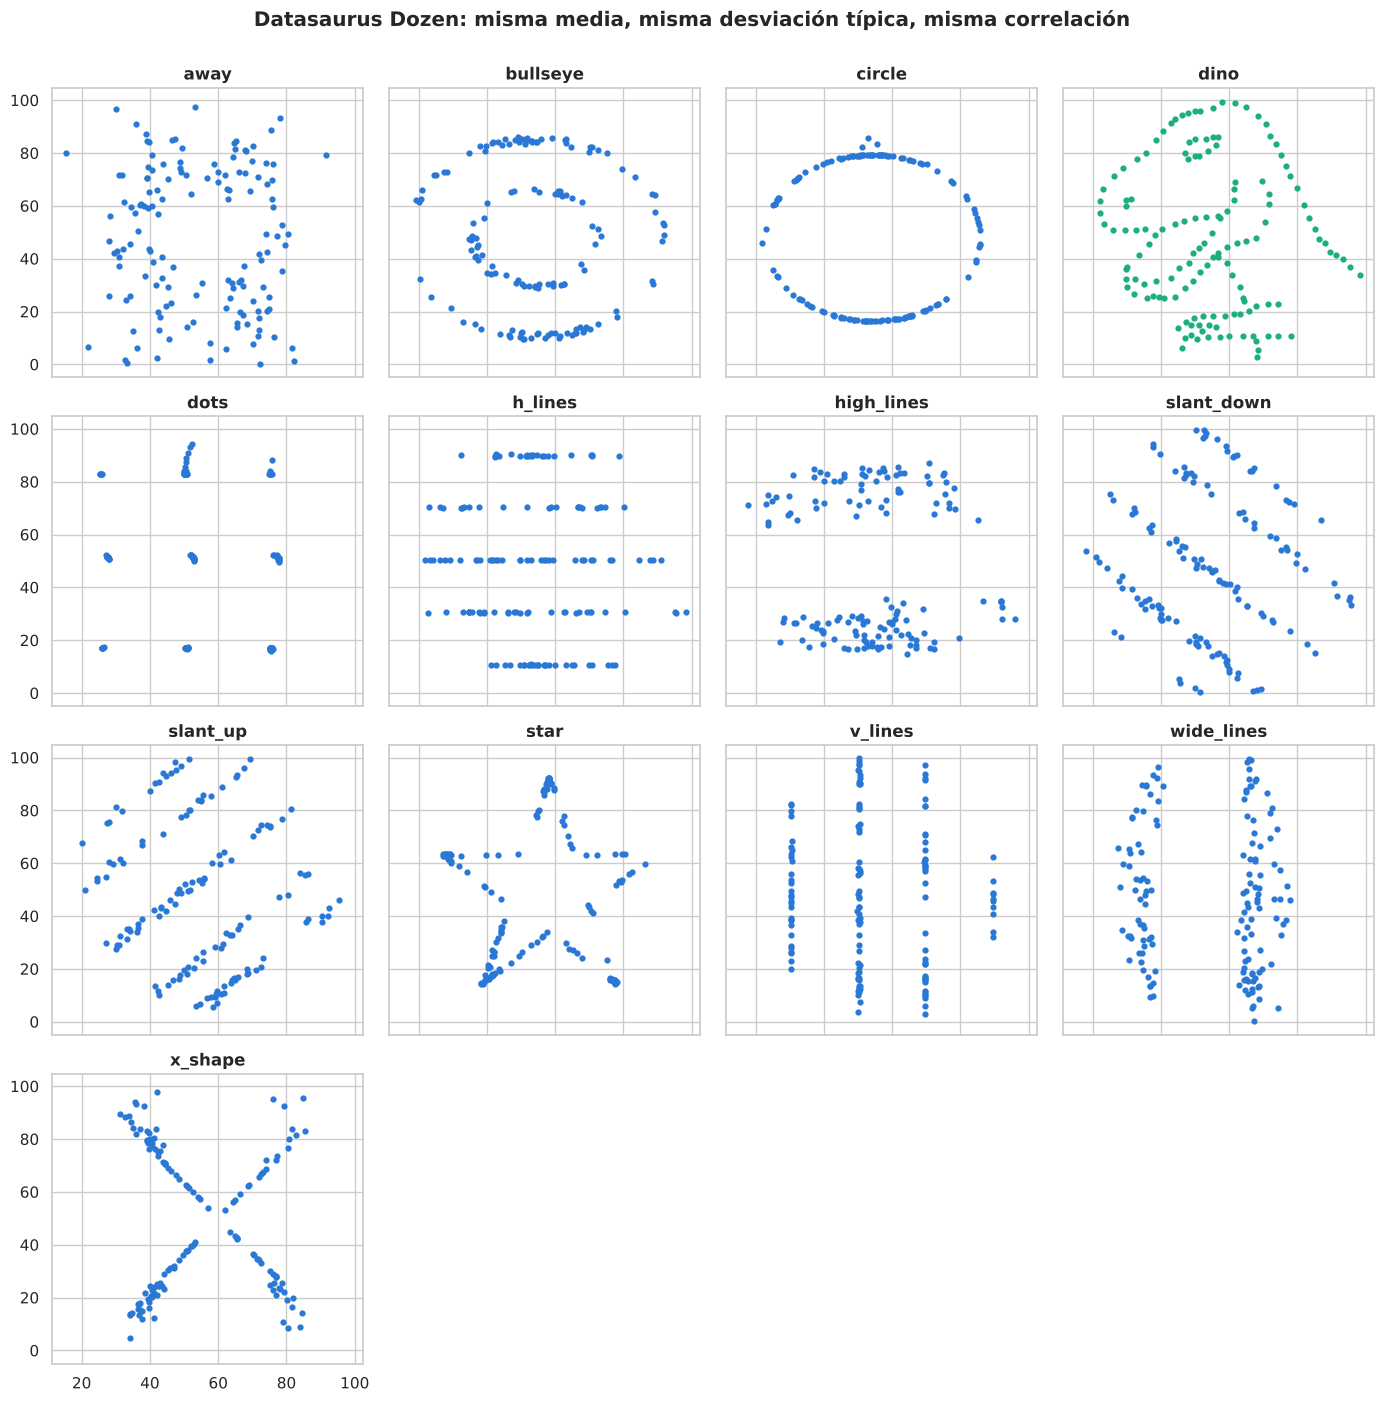

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14), sharex=True, sharey=True)
for ax, (nombre, g) in zip(axes.flat, dino.groupby("dataset")):
    ax.scatter(g["x"], g["y"], s=12, color=VERDE if nombre == "dino" else AZUL)
    ax.set_title(nombre)
for ax in axes.flat[dino["dataset"].nunique():]:
    ax.axis("off")
plt.suptitle("Datasaurus Dozen: misma media, misma desviación típica, misma correlación", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

🦖 Y todos tienen además prácticamente **la misma recta de regresión**, casi horizontal ($r \approx -0{,}06$, $R^2 \approx 0$).
Un $R^2$ de 0 no significa "no hay ninguna relación": significa "no hay relación **lineal**". ¡Hay un dinosaurio!

## 4. Cinco distribuciones, un solo diagrama de caja
El diagrama de caja resume una variable en 5 números (mín., Q1, mediana, Q3, máx.). ¿Basta con eso?

In [8]:
cajas = pd.read_csv(URL_DATOS + "mismo_boxplot.tsv", sep="\t").rename(columns={"Plot": "distribucion", "Values": "valor"})
cajas.groupby("distribucion")["valor"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
distribucion,,,,,,,,
left,"2,484.000",-1.180,3.900,-9.770,-2.690,-0.010,2.670,9.750
lines,"2,484.000",-0.830,3.880,-9.770,-2.690,-0.010,2.670,9.760
normal,"2,484.000",-0.000,3.840,-9.760,-2.680,-0.000,2.680,9.760
right,"2,484.000",1.170,3.900,-9.760,-2.680,-0.000,2.680,9.760
split,"2,484.000",-0.000,4.980,-9.770,-2.690,-0.000,2.680,9.760


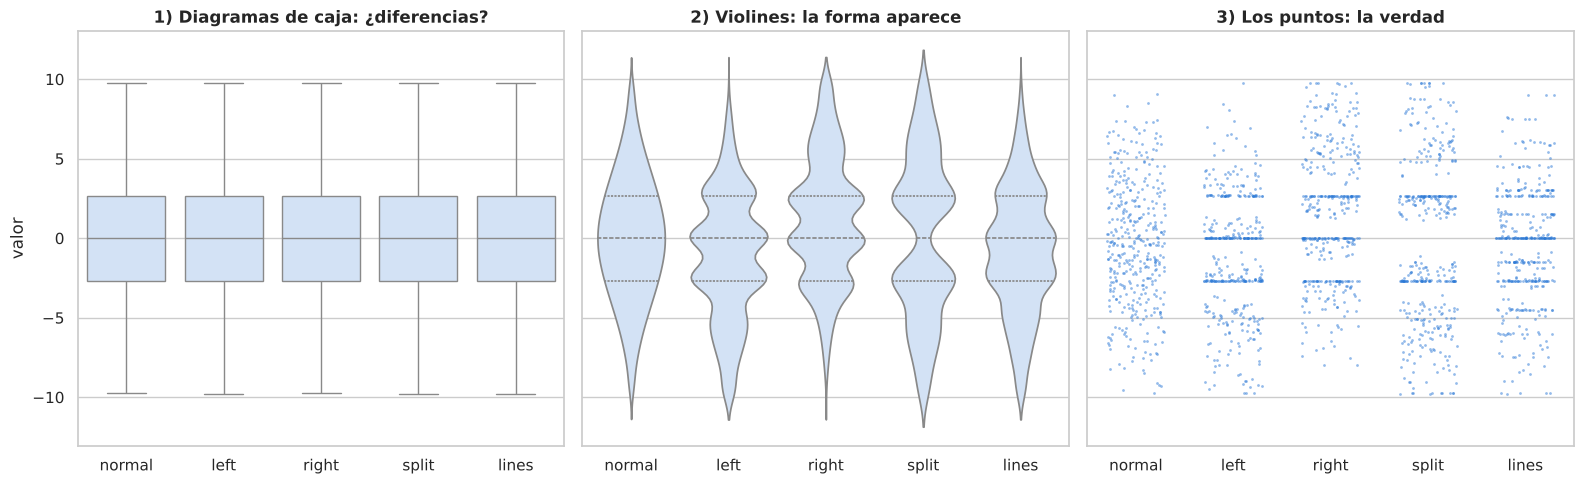

In [9]:
orden_c = ["normal", "left", "right", "split", "lines"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
sns.boxplot(data=cajas, x="distribucion", y="valor", order=orden_c, color="#cde2fb", ax=axes[0])
axes[0].set_title("1) Diagramas de caja: ¿diferencias?")
sns.violinplot(data=cajas, x="distribucion", y="valor", order=orden_c, color="#cde2fb", inner="quart", ax=axes[1])
axes[1].set_title("2) Violines: la forma aparece")
sns.stripplot(data=cajas.groupby("distribucion").sample(400, random_state=1), x="distribucion", y="valor",
              order=orden_c, size=2, alpha=0.5, color=AZUL, jitter=0.3, ax=axes[2])
axes[2].set_title("3) Los puntos: la verdad")
for a_ in axes: a_.set_xlabel("")
plt.tight_layout(); plt.show()

Las cinco tienen los mismos cinco números, pero solo `normal` es una distribución "suave"; `left` y `right` acumulan
los datos a un lado y a otro, `split` es **bimodal** (tiene un hueco en el centro) y `lines` concentra los datos en unos pocos valores.
¿Las distinguen las **medidas de forma**?

In [10]:
cajas.groupby("distribucion")["valor"].agg(asimetria="skew", curtosis="kurt").loc[orden_c].round(2)

,asimetria,curtosis
distribucion,,
normal,0.000,-0.350
left,-0.110,-0.480
right,0.120,-0.470
split,0.000,-0.980
lines,-0.040,-0.390


🤔 Solo **a medias**: la curtosis delata a `split` (muy negativa: poca masa en el centro) y la asimetría apunta a `left`/`right`,
pero con valores tan pequeños que no nos alarmarían. `lines` no la delata ningún número. **Ningún resumen sustituye al gráfico.**

## 5. La paradoja de Simpson: Berkeley, 1973
En otoño de 1973, la Universidad de California en Berkeley admitió en sus estudios de posgrado al **44 %** de los hombres que lo
solicitaron y solo al **35 %** de las mujeres. ¿Discriminación? Los datos de los seis departamentos más grandes
(Bickel, Hammel y O'Connell, *Science*, 1975):

In [11]:
berkeley = pd.DataFrame({
    "departamento": list("AABBCCDDEEFF"),
    "sexo": ["Hombre", "Mujer"] * 6,
    "solicitudes": [825, 108, 560, 25, 325, 593, 417, 375, 191, 393, 373, 341],
    "admitidos":   [512,  89, 353, 17, 120, 202, 138, 131,  53,  94,  22,  24],
})
berkeley["tasa_%"] = 100 * berkeley["admitidos"] / berkeley["solicitudes"]

total = berkeley.groupby("sexo")[["solicitudes", "admitidos"]].sum()
total["tasa_%"] = 100 * total["admitidos"] / total["solicitudes"]
total.round(1)

,solicitudes,admitidos,tasa_%
sexo,,,
Hombre,2691,1198,44.500
Mujer,1835,557,30.400


En el total de estos seis departamentos, las mujeres son admitidas en un porcentaje **mucho menor**. Ahora, **departamento a departamento**:

In [12]:
por_dep = berkeley.pivot(index="departamento", columns="sexo", values="tasa_%").round(1)
por_dep["¿quién gana?"] = np.where(por_dep["Mujer"] > por_dep["Hombre"], "Mujeres", "Hombres")
por_dep

sexo,Hombre,Mujer,¿quién gana?
departamento,,,
A,62.100,82.400,Mujeres
B,63.000,68.000,Mujeres
C,36.900,34.100,Hombres
D,33.100,34.900,Mujeres
E,27.700,23.900,Hombres
F,5.900,7.000,Mujeres


😮 **En 4 de los 6 departamentos las mujeres tienen una tasa de admisión MAYOR.** ¿Cómo puede ser que en total salga al revés?

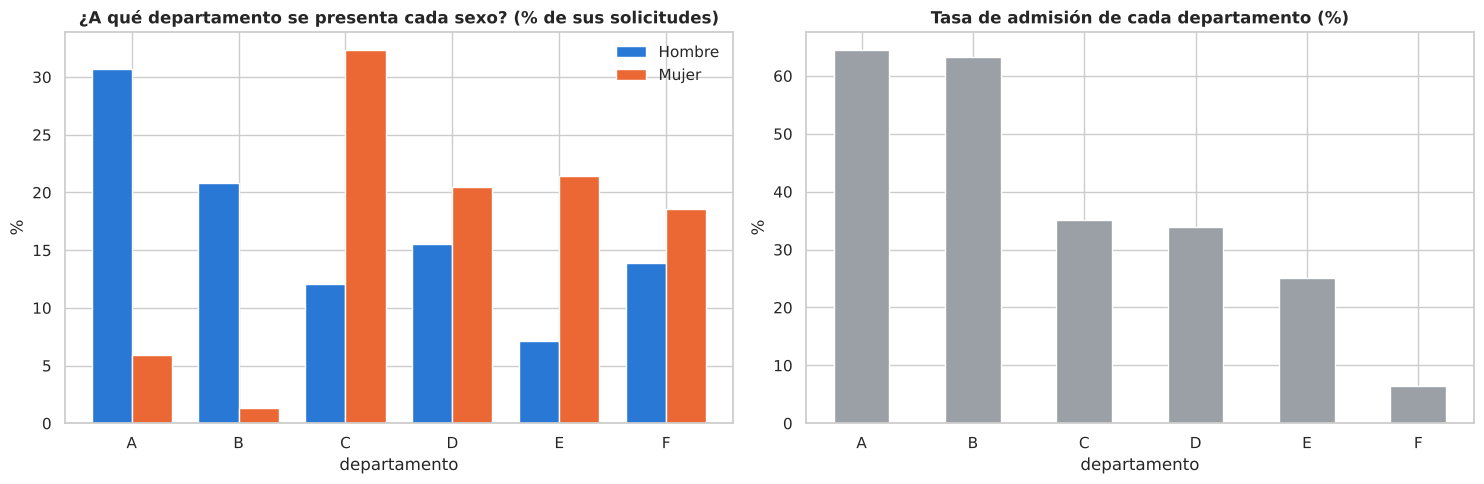

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sol = berkeley.pivot(index="departamento", columns="sexo", values="solicitudes")
(100 * sol / sol.sum()).plot.bar(ax=axes[0], color=[AZUL, NARANJA], width=0.75, rot=0)
axes[0].set_title("¿A qué departamento se presenta cada sexo? (% de sus solicitudes)")
axes[0].set_ylabel("%"); axes[0].legend(frameon=False)
tasa_dep = berkeley.groupby("departamento").apply(lambda g: 100 * g["admitidos"].sum() / g["solicitudes"].sum(), include_groups=False)
tasa_dep.plot.bar(ax=axes[1], color="#9aa0a6", rot=0)
axes[1].set_title("Tasa de admisión de cada departamento (%)"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

🎯 **La explicación:** los hombres se presentaron sobre todo a los departamentos **fáciles** (A y B, que admiten a más del 60 %);
las mujeres, a los **difíciles** (C a F, que admiten a menos del 35 %). La tasa total es una **media ponderada** de las tasas
de cada departamento, y los pesos (dónde se presenta cada grupo) son muy distintos.

Comprobémoslo: la tasa global de cada sexo es la media de sus tasas por departamento **ponderada por sus solicitudes**.

In [14]:
for s, g in berkeley.groupby("sexo"):
    ponderada = np.average(g["tasa_%"], weights=g["solicitudes"])
    simple = g["tasa_%"].mean()
    print(f"{s:6s}: media ponderada por solicitudes = {ponderada:.1f} %  |  media simple de los 6 departamentos = {simple:.1f} %")

Hombre: media ponderada por solicitudes = 44.5 %  |  media simple de los 6 departamentos = 38.1 %
Mujer : media ponderada por solicitudes = 30.4 %  |  media simple de los 6 departamentos = 41.7 %


🤔 Con la **media simple** (cada departamento pesa lo mismo), las mujeres salen por **encima**. Con la ponderada, por debajo.
Agrupar o no agrupar puede **invertir** una conclusión. Esto es la **paradoja de Simpson**, y es la misma idea que ya visteis
con la felicidad (media de países ≠ media de personas) y con los futbolistas (el exponente peso–altura con hombres y mujeres juntos).

### 🚀 Retos de la sesión 1
1. En el bar, ¿cuántos Bill Gates hacen falta para que la **mediana** cambie de forma apreciable? ¿Y el IQR?
2. Ajusta los modelos lineal, potencial y exponencial al conjunto II de Anscombe (con las fórmulas de los otros notebooks). ¿Alguno sirve? Prueba a ajustar una parábola con `np.polyfit(x, y, 2)`.
3. En el conjunto III, quita el atípico y recalcula la recta. ¿Cuánto cambian la pendiente y el $R^2$?
4. Calcula la asimetría y la curtosis de los 13 conjuntos del Datasaurus (para `x` y para `y`). ¿Se distinguen ahora?
5. Inventa tu propio "bar": una muestra de 20 números donde la media sea 50, pero ningún dato esté entre 40 y 60.

---
🏁 **Fin del notebook.**